# Assignment 2 - Supervised Learning with the Support Vector Machine (SVM) Algorithm

This notebook implements Support Vector Machine (SVM) classification on `air_quality_dataset.csv` (the same dataset used in Assignment 1) to enable a direct comparison with k-Nearest Neighbors (kNN), explore kernel behavior, visualize 2D decision boundaries, tune regularization ($C$), and summarize findings for the group presentation.


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv('air_quality_dataset.csv')

def categorize_aqi(pm25):
    if pm25 <= 35:
        return 'Good'
    elif pm25 <= 75:
        return 'Moderate'
    else:
        return 'Poor'

df['Air_Quality_Class'] = df['PM2.5'].apply(categorize_aqi)
print(f"Dataset Shape: {df.shape}")
print("\nClass Distribution:\n", df['Air_Quality_Class'].value_counts())

X = df.drop(columns=['Air_Quality_Class'])
y = df['Air_Quality_Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_ref = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn_ref.fit(X_train_scaled, y_train)
knn_acc = accuracy_score(y_test, knn_ref.predict(X_test_scaled))
print(f"\nAssignment 1 kNN Baseline Accuracy (k=5): {knn_acc:.4f}")

svm_linear = SVC(kernel='linear', C=1.0, random_state=42)
svm_linear.fit(X_train_scaled, y_train)
y_pred_linear = svm_linear.predict(X_test_scaled)

print(f"Assignment 2 Base SVM Accuracy (Linear, C=1.0): {accuracy_score(y_test, y_pred_linear):.4f}")
print("\nClassification Report (Linear SVM):\n", classification_report(y_test, y_pred_linear))

Dataset Shape: (500, 11)

Class Distribution:
 Air_Quality_Class
Moderate    285
Poor        115
Good        100
Name: count, dtype: int64

Assignment 1 kNN Baseline Accuracy (k=5): 0.8500
Assignment 2 Base SVM Accuracy (Linear, C=1.0): 0.9300

Classification Report (Linear SVM):
               precision    recall  f1-score   support

        Good       0.91      1.00      0.95        20
    Moderate       0.96      0.91      0.94        57
        Poor       0.88      0.91      0.89        23

    accuracy                           0.93       100
   macro avg       0.92      0.94      0.93       100
weighted avg       0.93      0.93      0.93       100



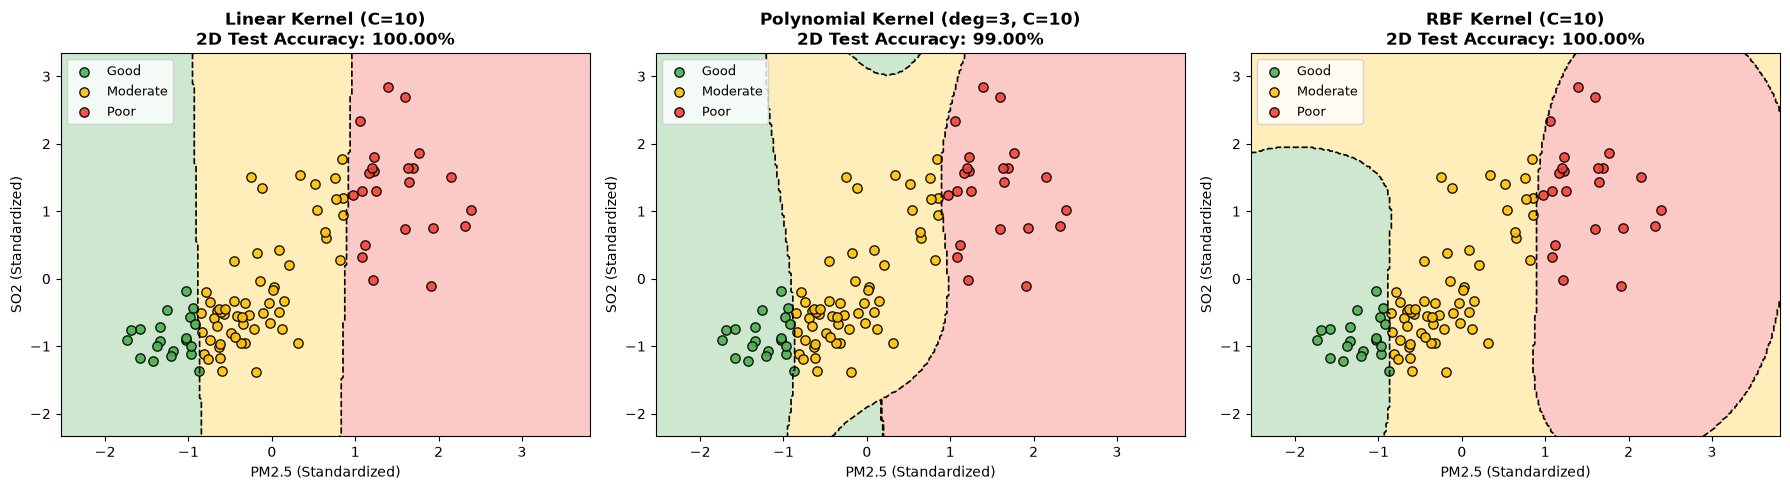

svm_decision_boundaries.png


In [ ]:
selected_features = ['PM2.5', 'SO2']
X_2d = df[selected_features]

le = LabelEncoder()
y_encoded = le.fit_transform(y)  
class_names = le.classes_

X_tr2, X_te2, y_tr2, y_te2 = train_test_split(
    X_2d, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

scaler_2d = StandardScaler()
X_tr2_s = scaler_2d.fit_transform(X_tr2)
X_te2_s = scaler_2d.transform(X_te2)

x_min, x_max = X_tr2_s[:, 0].min() - 0.6, X_tr2_s[:, 0].max() + 0.6
y_min, y_max = X_tr2_s[:, 1].min() - 0.6, X_tr2_s[:, 1].max() + 0.6
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
vis_kernels = [('linear', 'Linear Kernel (C=10)'), ('poly', 'Polynomial Kernel (deg=3, C=10)'), ('rbf', 'RBF Kernel (C=10)')]
colors = ['#4CAF50', '#FFC107', '#F44336'] 

for ax, (k_name, title) in zip(axes, vis_kernels):
    clf_2d = SVC(kernel=k_name, C=10.0, degree=3, random_state=42)
    clf_2d.fit(X_tr2_s, y_tr2)
    acc_2d = accuracy_score(y_te2, clf_2d.predict(X_te2_s))
    
    Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.28, levels=[-0.5, 0.5, 1.5, 2.5], colors=colors)
    ax.contour(xx, yy, Z, levels=[0.5, 1.5], colors='black', linewidths=1.2, linestyles='--')
    
    for idx, cls_label in enumerate(class_names):
        mask = (y_te2 == idx)
        ax.scatter(
            X_te2_s[mask, 0], X_te2_s[mask, 1],
            c=colors[idx], label=cls_label, edgecolors='k', s=45, alpha=0.9
        )
    ax.set_title(f"{title}\n2D Test Accuracy: {acc_2d:.2%}", fontsize=12, fontweight='bold')
    ax.set_xlabel(f"{selected_features[0]} (Standardized)", fontsize=10)
    ax.set_ylabel(f"{selected_features[1]} (Standardized)", fontsize=10)
    ax.legend(loc='upper left', fontsize=9)

plt.tight_layout()
plt.savefig('svm_decision_boundaries.png', dpi=300, bbox_inches='tight')
plt.show()